<h1>MINI PROJECT MARKET BASKET ANALYTICS</h1>
<H2>ANALISIS Market Basket Analysis- Groceries_dataset</H2>

<h3>A. Import Library</h3>

<p>
    import library yang dibutuhkan untuk melakukan Pre Processing Data
</p>

In [41]:
import pandas as pd
import numpy as np
from mlxtend.frequent_patterns import apriori, association_rules
import matplotlib.pyplot as plt
import seaborn as sns

<H3>B. Import File Data</H3>

<p>
     import file data Market Basket Analytics.csv
</p>

In [3]:
df = pd.read_csv('Market Basket Analysis- Groceries_dataset.csv')
df.head(10)

,Member_number,Date,itemDescription
0,1808,21-07-2015,tropical fruit
1,2552,05-01-2015,whole milk
2,2300,19-09-2015,pip fruit
3,1187,12-12-2015,other vegetables
4,3037,01-02-2015,whole milk
5,4941,14-02-2015,rolls/buns
6,4501,08-05-2015,other vegetables
7,3803,23-12-2015,pot plants
8,2762,20-03-2015,whole milk
9,4119,12-02-2015,tropical fruit


<h3>C. Data Exploration</h3>

<p>Eksplorasi Data untuk Memeriksa Konsistensi Data</p>

<h4>1. cek tipe data setiap kolom</h4>

In [4]:
df.dtypes

Member_number      int64
Date                 str
itemDescription      str
dtype: object

<b>Hasil pengamatan dari df.dtypes</b>
<p>
    Dataframe  Market Basket Analytics memiliki 3 kolom dan 38765 baris
    <br>Kolom  Date bertipe data string harus diubah menjadi date
    <br>Kolom ItemDescription bertipe data string dan sudah sesuai
    <br>Kolom Member_number bertipe data int64 harus diubah menjadi string karena nilai pada kolom ini adalah nilai unik kostumer 
</p>

<h4>2. Pemeriksaan kelengkapan data  </h4>

In [24]:
jumlah_baris = df.shape[0]
jumlah_kolom = df.shape[1]
jumlah_duplikasi = df.duplicated().sum()
jumlah_missing_values = df.isnull().sum().sum()

df_pemeriksaan = pd.DataFrame({
    'Indikator Pemeriksaan': ['Jumlah Baris', 'Jumlah Kolom', 'Jumlah Duplikasi', 'Jumlah Missing Values'],
    'Jumlah Pemeriksaan': [jumlah_baris, jumlah_kolom, jumlah_duplikasi, jumlah_missing_values]
})

# menambahkan format angka dengan pemisah ribuan
df_pemeriksaan['Jumlah Pemeriksaan'] = df_pemeriksaan['Jumlah Pemeriksaan'].apply(lambda x: f"{x:,}")
df_pemeriksaan

,Indikator Pemeriksaan,Jumlah Pemeriksaan
0,Jumlah Baris,"38,765"
1,Jumlah Kolom,4
2,Jumlah Duplikasi,759
3,Jumlah Missing Values,0


<b> Hasil pengamatan </b>
<p>
    Dataframe  Market Basket Analytics memiliki 3 kolom dan 38765 baris
    <br>diketahui 759 data yang duplikasi
    <br>tidak ada missing values
</p>

<h4>3. Cek Persentase Duplikasi  </h4>

In [32]:
# 1. Hitung jumlah duplikasi dan persentase duplikasi
jumlah_duplikasi = df.duplicated().sum()
persentase_duplikasi = (jumlah_duplikasi / total_baris) * 100
# 2. Buat tabel ringkasan (DataFrame)
tabel_ringkasan = pd.DataFrame({
    'Keterangan': [ 'Jumlah Duplikasi' ],
    'Nilai': [jumlah_duplikasi],
    'Persentase Duplikasi': [f"{persentase_duplikasi:.2f}%"]
})
# Tampilkan tabel
tabel_ringkasan

,Keterangan,Nilai,Persentase Duplikasi
0,Jumlah Duplikasi,759,1.96%


<b> Hasil pengamatan </b>
<p>
    Persentase dari jumlah duplikasi adalah 1.96% dan butuh eksplorasi lebih lanjut untuk menentukan tindakan yang harus dilakukan terhadap nilai yang duplikasi
</p>

<h4> 4. Cek Konsistensi Data  </h4>

In [13]:
#checking nilai kolom yang unik
cat_cols = df.select_dtypes(include=['object', 'string', 'category', 'bool','datetime64','integer'])

df_ceksdf = pd.DataFrame([{
    'Nama_Kolom': col,
    'nilai_Unik': cat_cols[col].dropna().unique().tolist(),
    'Jumlah_Unik': cat_cols[col].nunique(dropna=True)
} for col in cat_cols.columns])

pd.set_option('display.max_colwidth', 80)
df_ceksdf

,Nama_Kolom,nilai_Unik,Jumlah_Unik
0,Member_number,"[1808, 2552, 2300, 1187, 3037, 4941, 4501, 3803, 2762, 4119, 1340, 2193, 199...",3898
1,Date,"[21-07-2015, 05-01-2015, 19-09-2015, 12-12-2015, 01-02-2015, 14-02-2015, 08-...",728
2,itemDescription,"[tropical fruit, whole milk, pip fruit, other vegetables, rolls/buns, pot pl...",167


In [10]:
# Export dataframe untuk dianalisa oleh AI nilai yang tidak konsisten 
df_ceksdf.to_csv('cek_konsisten_market_data.csv', index=False)

<b> Hasil pengamatan </b>
<p>
    Berdasarkan penelusuran AI, nilai pada kolom member_number sudah konsisten, kolom date sudah konsisten kemudian juga kolom itemDescription terdapat spasi berlebih pada nilai 'cream cheese ' dan 'roll products ' perlu dilakukan penghapusan spasi yang berlebih untuk memudahkan proses analisis lalu daftar nama ini adalah  sebutan/nama umum barang yang ditulis oleh pembuat dataset untuk menyederhanakan dari  ribuan produk belanjaan yang berbeda merek bisa menjadi ratusan nama jenis barang saja. Berdasarkan jumlah unik setiap kolom tidak ditemukan kolom yang mewakili setiap transaksi karena jumlahnya tidak sama dengan total baris yaitu 38765 perlu dibuatkan kolom baru untuk mengelompokkan semua barang belanjaan seorang pelanggan di hari yang sama ke dalam satu "wadah" keranjang</p>

<h4>6. Hasil Data Exploration   </h4>

<b> Hasil pengamatan </b>
<p>
    Ditemukan beberapa isu dalam data antara lain tipe data member_number adalah integer harus diganti dengan string karena merupakan perwakilan identitas pelanggan lalu tipe data Date adalah string perlu dilakukan pengubahan tipe data menjadi Datetime, kemudian  ditemukannya data yang duplikat berjumlah 759 baris(1,96%) tindakan terhadap duplikasi akan ditentukan setelah penambahan kolom kemudian dilakukan pengecekan duplikasi kembali, lalu ditemukan nilai yang memiliki spasi berlebih pada nilai kolom itemDescription berlabel 'cream cheese ' dan 'roll products ' akan dilakukan penghilangan spasi berlebih dan terakhir akan dilakukan penambahan kolom baru untuk mengelompokkan semua barang belanjaan seorang pelanggan di hari yang sama dengan cara menggabungkan kolom member_number dengan date, pengubahan tipe data member_ number akan dilakukan terlebih dahulu kemudian penambahan kolom akan dilakukan selanjutnya sebelum mengubah tipe data kolom Date menjadi datetime untuk memungkinkan penggabungan 2 kolom </p>

<h3>D. Data Cleaning</h3>

<h4>1. Mengubah tipe data Member_number    </h4>

In [15]:
# Mengubah Member_number menjadi string
df['Member_number'] = df['Member_number'].astype(str)

In [16]:
# cek kembali tipe data
df.dtypes

Member_number      str
Date               str
itemDescription    str
dtype: object

<h4>2. Menambah kolom baru untuk identifikasi keranjang    </h4>

In [17]:
# Menggabungkan Member_number (string) dengan Date masih bertipe string
df['Transaction_ID'] = df['Member_number'] + '_' + df['Date']

In [18]:
# cek kolom baru pada data
df.dtypes

Member_number      str
Date               str
itemDescription    str
Transaction_ID     str
dtype: object

In [49]:
# cek jumlah nilai unik per kolom
#checking kolom yang mewakili nilai setiap baris
for col in df.columns:
    jumlah_unik = df[col].nunique()
    print(f"Kolom {col}: {jumlah_unik} nilai unik")

Kolom Member_number: 3898 nilai unik
Kolom Date: 728 nilai unik
Kolom itemDescription: 167 nilai unik
Kolom Transaction_ID: 14963 nilai unik


<h4>3.Mengubah tipe data Date    </h4>

In [21]:
#  Mengubah Date menjadi tipe data datetime
df['Date'] = pd.to_datetime(df['Date'], format='%d-%m-%Y')

In [23]:
df.dtypes

Member_number                 str
Date               datetime64[us]
itemDescription               str
Transaction_ID                str
dtype: object

<h4>4. Menghapus spasi berlebih (white space)    </h4>

In [31]:
#  Menghapus spasi berlebih pada kolom itemDescription
df['itemDescription'] = df['itemDescription'].str.strip()

<h4>5. Cek ulang Konsistensi nilai kolom   </h4>

In [29]:
#checking nilai kolom yang unik
cat_cols = df.select_dtypes(include=['object', 'string', 'category', 'bool','datetime64','integer'])

df_ceksdf = pd.DataFrame([{
    'Nama_Kolom': col,
    'nilai_Unik': cat_cols[col].dropna().unique().tolist(),
    'Jumlah_Unik': cat_cols[col].nunique(dropna=True)
} for col in cat_cols.columns])

pd.set_option('display.max_colwidth', 80)
df_ceksdf

,Nama_Kolom,nilai_Unik,Jumlah_Unik
0,Member_number,"[1808, 2552, 2300, 1187, 3037, 4941, 4501, 3803, 2762, 4119, 1340, 2193, 199...",3898
1,Date,"[2015-07-21 00:00:00, 2015-01-05 00:00:00, 2015-09-19 00:00:00, 2015-12-12 0...",728
2,itemDescription,"[tropical fruit, whole milk, pip fruit, other vegetables, rolls/buns, pot pl...",167
3,Transaction_ID,"[1808_21-07-2015, 2552_05-01-2015, 2300_19-09-2015, 1187_12-12-2015, 3037_01...",14963


In [30]:
# Export dataframe untuk dianalisa oleh AI nilai yang tidak konsisten 
df_ceksdf.to_csv('cek_ulang_konsisten_market_data.csv', index=False)

<b> Hasil pengamatan </b>
<p>
    Berdasarkan penelusuran AI, nilai pada semua kolom sudah konsisten </p>

<h4>6. Cek nilai kolom yang duplikasi</h4>

In [35]:
duplikat_df = df[df.duplicated(subset=['Transaction_ID', 'itemDescription'], keep=False)]
duplikat_df.sort_values(by=['Transaction_ID', 'itemDescription'])

,Member_number,Date,itemDescription,Transaction_ID
33098,1003,2014-02-27,rolls/buns,1003_27-02-2014
37649,1003,2014-02-27,rolls/buns,1003_27-02-2014
15099,1005,2014-01-09,rolls/buns,1005_09-01-2014
31248,1005,2014-01-09,rolls/buns,1005_09-01-2014
7532,1006,2015-06-14,frankfurter,1006_14-06-2015
...,...,...,...,...
24043,4981,2015-01-10,margarine,4981_10-01-2015
8109,4988,2015-10-29,rolls/buns,4988_29-10-2015
24258,4988,2015-10-29,rolls/buns,4988_29-10-2015
33585,4992,2014-02-24,margarine,4992_24-02-2014


<b> Hasil pengamatan </b>
<p>
    Ditemukan barang yang sama pada Transactions_ID yang sama, hal ini mengartikan customer tersebut membeli barang rolls/buns sebanyak 2 buah. karena analisis ini hanya membutuhkan adanya barang masuk keranjang atau tidak maka nilai yang duplikasi akan dihapus untuk analisis apriori</p>

<h4>7. Menghapus kolom yang duplikasi</h4>

In [36]:
df = df.drop_duplicates(subset=['Transaction_ID', 'itemDescription'])

<h4>8. Cek ulang kelengkapan data</h4>

In [37]:
jumlah_baris = df.shape[0]
jumlah_kolom = df.shape[1]
jumlah_duplikasi = df.duplicated().sum()
jumlah_missing_values = df.isnull().sum().sum()

df_pemeriksaan = pd.DataFrame({
    'Indikator Pemeriksaan': ['Jumlah Baris', 'Jumlah Kolom', 'Jumlah Duplikasi', 'Jumlah Missing Values'],
    'Jumlah Pemeriksaan': [jumlah_baris, jumlah_kolom, jumlah_duplikasi, jumlah_missing_values]
})

# menambahkan format angka dengan pemisah ribuan
df_pemeriksaan['Jumlah Pemeriksaan'] = df_pemeriksaan['Jumlah Pemeriksaan'].apply(lambda x: f"{x:,}")
df_pemeriksaan

,Indikator Pemeriksaan,Jumlah Pemeriksaan
0,Jumlah Baris,"38,006"
1,Jumlah Kolom,4
2,Jumlah Duplikasi,0
3,Jumlah Missing Values,0


<h4>8. Buat kolom baru untuk keutuhan analisis</h4>

In [49]:
df['basket_size'] = df.groupby('Transaction_ID')['itemDescription'].transform('count')
# 2. MEMBUAT FITUR WAKTU (Mengekstrak nama hari dan bulan)
df['Day_Name'] = df['Date'].dt.day_name()
df['Month'] = df['Date'].dt.month_name()
# Membuat segmentasi/kategori keranjang belanja
conditions = [
    (df['basket_size'] <= 2),
    (df['basket_size'] > 2) & (df['basket_size'] <= 4),
    (df['basket_size'] > 4)
]
choices = ['Small (1-2 items)', 'Medium (3-4 items)', 'Large (>4 items)']
df['Basket_Category'] = np.select(conditions, choices, default='Unknown')

<h4>8. Cek outlier</h4>

In [53]:
# 2. PERHITUNGAN IQR (Sebagai bukti matematis pencarian outlier)
# Kita ambil data unik per keranjang agar perhitungannya akurat
basket_unik = df.drop_duplicates(subset=['Transaction_ID'])['basket_size']

Q1 = basket_unik.quantile(0.25)
Q3 = basket_unik.quantile(0.75)
IQR = Q3 - Q1
batas_atas = Q3 + (1.5 * IQR)

print(f"--- Outlier IQR ---")
print(f"Batas Atas Outlier: {batas_atas}")
print(f"Jumlah transaksi outlier (> {batas_atas} item): {len(basket_unik[basket_unik > batas_atas])}\n")

--- Outlier IQR ---
Batas Atas Outlier: 4.5
Jumlah transaksi outlier (> 4.5 item): 746



<h4>8. Cek outlier per kolom</h4>

In [56]:
# 4. MENJALANKAN ANALISIS PROPORSI (Dominasi Univariate)
data_proporsi = []
kolom_kategori = ['Member_number','Date','itemDescription', 'Day_Name', 'Month', 'Basket_Category']

for col in kolom_kategori:
    # Mengambil nilai paling sering muncul dan menghitung persentasenya
    nilai_terbesar = df[col].value_counts().index[0]
    jumlah = df[col].value_counts().iloc[0]
    total_data = len(df[col].dropna())
    persentase = (jumlah / total_data) * 100
    
    # Menentukan status skenario
    if persentase > 50:
        status = "Dominasi Kuat (> 50%)"
    elif persentase > 25:
        status = "Dominasi Signifikan (Lebih Besar)"
    else:
        status = "Distribusi Merata (Tidak Dominan)"
        
    data_proporsi.append([col, nilai_terbesar, jumlah, f"{persentase:.2f}%", status])

# Tampilkan Hasil Akhir
df_proporsi = pd.DataFrame(data_proporsi, columns=['Nama Kolom', 'Nilai Kolom (Terbesar)', 'Jumlah', 'Persentase', 'Status Skenario'])
# print(df_proporsi.to_string(index=False))
df_proporsi

,Nama Kolom,Nilai Kolom (Terbesar),Jumlah,Persentase,Status Skenario
0,Member_number,3180,35,0.09%,Distribusi Merata (Tidak Dominan)
1,Date,2015-01-21 00:00:00,96,0.25%,Distribusi Merata (Tidak Dominan)
2,itemDescription,whole milk,2363,6.22%,Distribusi Merata (Tidak Dominan)
3,Day_Name,Thursday,5510,14.50%,Distribusi Merata (Tidak Dominan)
4,Month,August,3431,9.03%,Distribusi Merata (Tidak Dominan)
5,Basket_Category,Small (1-2 items),20229,53.23%,Dominasi Kuat (> 50%)


<h4>9. Analisis univariate, bivariate, multivariate</h4>

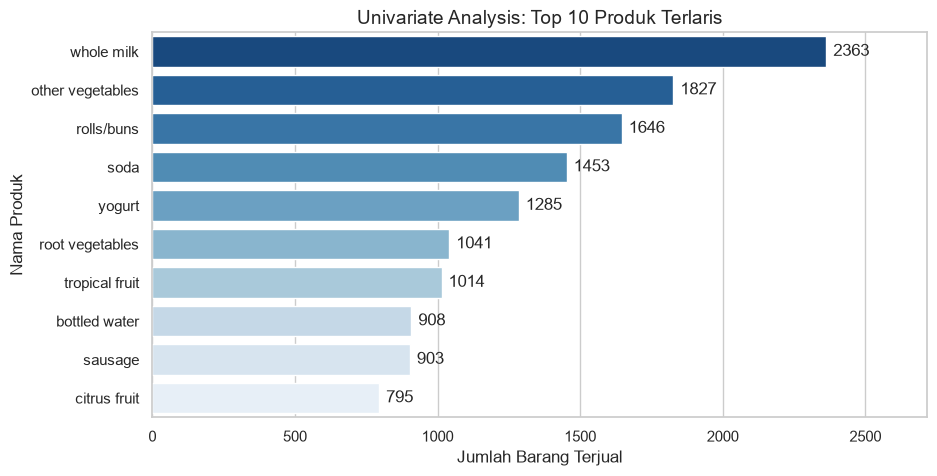

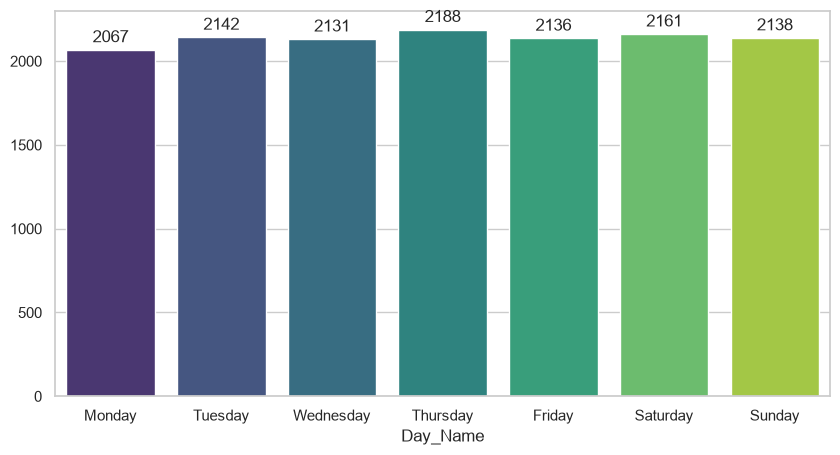

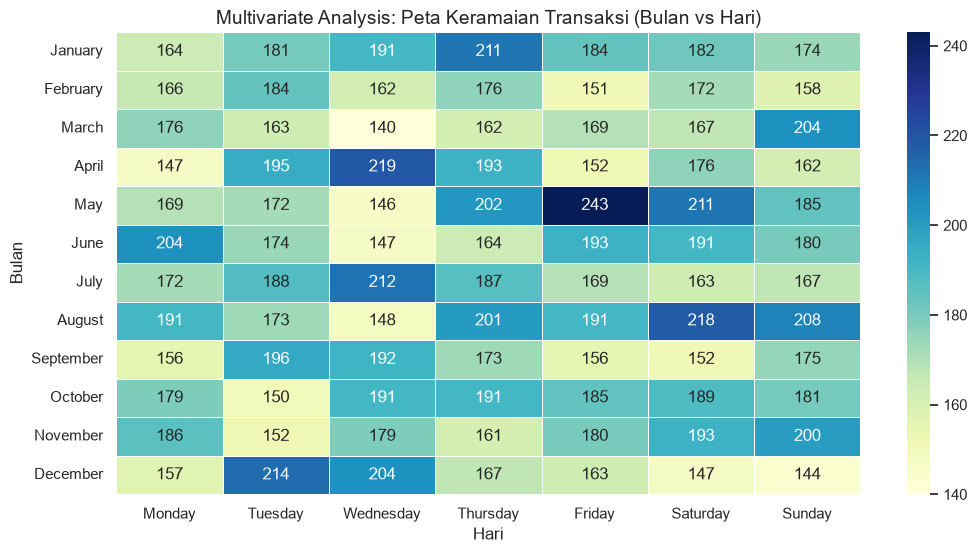

In [64]:
sns.set_theme(style="whitegrid")

# ==========================================
# 1. UNIVARIATE ANALYSIS
# ==========================================
plt.figure(figsize=(10, 5))
top_10_items = df['itemDescription'].value_counts().head(10)

# Tambahkan hue dan legend=False untuk menghilangkan warning merah muda
ax1 = sns.barplot(x=top_10_items.values, y=top_10_items.index, 
                  palette='Blues_r', hue=top_10_items.index, legend=False)

# Looping untuk memastikan semua batang mendapatkan label angka
for container in ax1.containers:
    ax1.bar_label(container, padding=5, fmt='%g')

plt.title('Univariate Analysis: Top 10 Produk Terlaris', fontsize=14)
plt.xlabel('Jumlah Barang Terjual')
plt.ylabel('Nama Produk')
plt.xlim(0, top_10_items.max() * 1.15) 
plt.show()

# ==========================================
# 2. BIVARIATE ANALYSIS
# ==========================================
plt.figure(figsize=(10, 5))
tren_hari = df.groupby('Day_Name')['Transaction_ID'].nunique().reindex(
    ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']
)

# Tambahkan hue dan legend=False untuk menghilangkan warning merah muda
ax2 = sns.barplot(x=tren_hari.index, y=tren_hari.values, 
                  palette='viridis', hue=tren_hari.index, legend=False)

# Looping untuk memastikan semua batang mendapatkan label angka
for container in ax2.containers:
    ax2.bar_label(container, padding=3, fmt='%g')
plt.figure(figsize=(12, 6))

# Grouping transaksi berdasarkan Bulan dan Hari
pivot_multi = df.groupby(['Month', 'Day_Name'])['Transaction_ID'].nunique().unstack()

# Urutkan hari
hari_order = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']
# Urutkan bulan sesuai kalender
bulan_order = ['January', 'February', 'March', 'April', 'May', 'June', 
               'July', 'August', 'September', 'October', 'November', 'December']

pivot_multi = pivot_multi.reindex(index=bulan_order, columns=hari_order)

sns.heatmap(pivot_multi, cmap='YlGnBu', annot=True, fmt='g', linewidths=.5)
plt.title('Multivariate Analysis: Peta Keramaian Transaksi (Bulan vs Hari)', fontsize=14)
plt.xlabel('Hari')
plt.ylabel('Bulan')
plt.show()

<h4>10. Encoding kolom itemDescription untuk analisa</h4>

In [71]:
# ONE-HOT ENCODING (Membuat Basket Matrix)
df_encode = pd.get_dummies(df['itemDescription'], dtype=int)
basket_encoded = df_encode.groupby(df['Transaction_ID']).max().astype(bool)
basket_encoded.head(10)

,Instant food products,UHT-milk,abrasive cleaner,artif. sweetener,baby cosmetics,bags,baking powder,bathroom cleaner,beef,berries,...,turkey,vinegar,waffles,whipped/sour cream,whisky,white bread,white wine,whole milk,yogurt,zwieback
Transaction_ID,,,,,,,,,,,,,,,,,,,,,
1000_15-03-2015,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,True,True,False
1000_24-06-2014,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,True,False,False
1000_24-07-2015,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
1000_25-11-2015,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
1000_27-05-2015,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
1001_02-05-2015,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
1001_07-02-2014,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,True,False,False
1001_12-12-2014,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,True,False,False
1001_14-04-2015,False,False,False,False,False,False,False,False,True,False,...,False,False,False,False,False,True,False,False,False,False


<h4>11. Pemodelan Algoritma Apriori dan Association Rules</h4>

In [91]:
# STEP 1: Mencari Himpunan Produk yang Sering Muncul (Frequent Itemsets)
frequent_itemsets = apriori(basket_encoded, min_support=0.001, use_colnames=True)

# STEP 2: Membentuk Association Rules
rules = association_rules(frequent_itemsets, metric="lift", min_threshold=1.0)

# STEP 3: Mengurutkan dari nilai Lift tertinggi
rules = rules.sort_values('lift', ascending=False)

# STEP 4: Menghilangkan aturan yang kombinasinya bolak-balik berulang (TAMBAHKAN DI SINI)
rules['pair'] = rules.apply(lambda row: tuple(sorted(list(row['antecedents'] | row['consequents']))), axis=1)
rules_unique = rules.drop_duplicates(subset=['pair']).drop(columns=['pair'])

# STEP 5: Tampilkan 5 kombinasi produk unik teratas
rules_unique[['antecedents', 'consequents', 'support', 'confidence', 'lift']].head(5)

,antecedents,consequents,support,confidence,lift
238,frozenset({sausage}),"frozenset({yogurt, whole milk})",0.001470,0.024363,2.182917
86,frozenset({citrus fruit}),frozenset({specialty chocolate}),0.001403,0.026415,1.653762
122,frozenset({tropical fruit}),frozenset({flour}),0.001069,0.015779,1.617141
20,frozenset({beverages}),frozenset({sausage}),0.001537,0.092742,1.536764
232,frozenset({sausage}),"frozenset({soda, whole milk})",0.001069,0.017719,1.523708


<h4>12. Visualisasi Association Rules </h4>

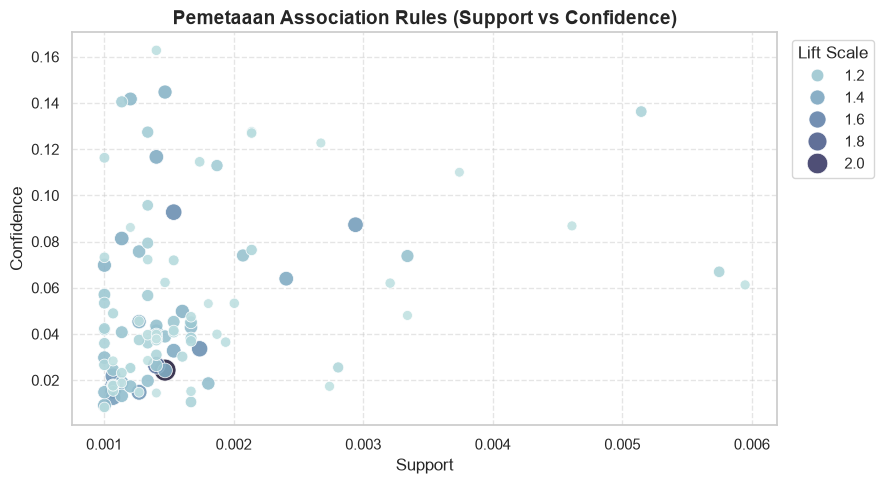

In [87]:
# STEP 12: Visualisasi Scatter Plot Association Rules
plt.figure(figsize=(9, 5))

# Menggunakan rules_unique agar titik yang divisualisasikan adalah kombinasi yang bersih
sns.scatterplot(
    data=rules_unique, 
    x='support', 
    y='confidence', 
    hue='lift',
    size='lift',
    palette='ch:start=.2,rot=-.3', 
    sizes=(50, 250),
    alpha=0.9
)

plt.title('Pemetaaan Association Rules (Support vs Confidence)', fontsize=14, fontweight='bold')
plt.xlabel('Support', fontsize=12)
plt.ylabel('Confidence', fontsize=12)
plt.grid(True, linestyle='--', alpha=0.5)

# Memindahkan legenda ke luar grafik agar tidak menutupi titik data
plt.legend(bbox_to_anchor=(1.01, 1), loc='upper left', title='Lift Scale')
plt.tight_layout()
plt.show()

<h4>13. Ekspor data yang sudah bersih dan hasil apriori </h4>

In [94]:
# 1. Menyaring kolom yang dibutuhkan untuk rules_unique
rules_export = rules_unique[['antecedents', 'consequents', 'support', 'confidence', 'lift']].copy()

# 2. Menghilangkan tulisan "frozenset" agar rapi saat dibaca di Power BI
rules_export['antecedents'] = rules_export['antecedents'].apply(lambda x: ', '.join(list(x)))
rules_export['consequents'] = rules_export['consequents'].apply(lambda x: ', '.join(list(x)))

# 3. Export kedua dataset ke CSV (tanpa menyertakan index)
df.to_csv('Market_Basket_Analysis_cleaned.csv', index=False)
rules_export.to_csv('apriori_rules.csv', index=False)

print("Berhasil! Data siap diload ke Power BI.")

Berhasil! Data siap diload ke Power BI.
